# Vehicle detection with SqueezeNet and YOLOv3

This experiment predicts **vehicle bounding boxes**, rather than one label for
an entire image. It retains a compact, two-head YOLOv3 design from an earlier
local experiment. The backbone is SqueezeNet 1.1, not Darknet-53.

The `.py` files implement the model, training, evaluation, and augmentation.
This notebook explains the experiment and reads its saved results. Real photos
and annotations stay local; no photograph is displayed or embedded here.

**Sources:** [YOLOv3 paper](https://arxiv.org/abs/1804.02767),
[licensed Python reference](https://github.com/westerndigitalcorporation/YOLOv3-in-PyTorch),
and [implementation/data notices](../THIRD_PARTY_NOTICES.md).
The adapted decoding/loss file retains BSD-3-Clause; the project's other own
contributions use MIT. These licenses do not license the local photographs.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when the kernel starts in the repository root or this module directory.
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
assert (ROOT / "object_detection").is_dir(), "Start in the repository or module directory."
RESULTS = ROOT / "object_detection" / "results"


## 1. Reproduce the experiment or read the saved run

The main command is `python -m object_detection.run_experiment`. It trains all
four comparisons, selects checkpoints using validation AP50, evaluates the test
set, and saves seven aggregate artifacts. See the module README to prepare an
authorized local copy of the image dataset once.

Keep `RETRAIN = False` to regenerate the analysis from the public results without
private data. Set it to `True` to call the same training code on the local data;
this takes several minutes and replaces the saved results. No weights or image
previews are exported in either case.

In [2]:
RETRAIN = False
if RETRAIN:
    from object_detection.run_experiment import run_experiment, save_results
    trained = run_experiment(epochs=30, threads=2)
    save_results(trained, RESULTS)

result = {name: pd.read_csv(RESULTS / f"{name}.csv")
          for name in ("metrics", "history", "pr_curve")}
result["metadata"] = json.loads((RESULTS / "metadata.json").read_text())
metadata = result["metadata"]
print(f"Recorded run: {metadata['epochs']} epochs per configuration; CPU; seed {metadata['seed']}.")
print(f"Source images: {metadata['images']}; boxes: {metadata['objects']}; "
      f"unique pixel groups: {metadata['unique_pixel_groups']}.")


Recorded run: 30 epochs per configuration; CPU; seed 42.
Source images: 295; boxes: 336; unique pixel groups: 246.


## 2. Data and leakage controls

Pixels are divided by 255 and resized to 227 × 227. Bounding boxes undergo the
same scaling. Exact RGB duplicates stay together in an approximately 60/20/20
train/validation/test split. This is important because several local images are
identical. Near-duplicates and related scenes can still cross splits: no sequence
identifiers are available.

Only the training boxes are used to estimate six anchors, by clustering widths
and heights with an IoU-based distance. Validation chooses checkpoints and the
configuration. The test set is evaluated after these choices are fixed.

In [3]:
display(pd.DataFrame({"images": metadata["split_counts"],
                      "objects": metadata["split_object_counts"]}))
anchors = pd.DataFrame([
    {"head": head, "width": pair[0], "height": pair[1]}
    for head, group in zip(("14x14 (coarse)", "28x28 (fine)"), metadata["anchors"])
    for pair in group
])
display(anchors.round(2))


,images,objects
train,179,206
validation,56,62
test,60,68


,head,width,height
0,14x14 (coarse),121.51,139.85
1,14x14 (coarse),129.52,148.97
2,14x14 (coarse),137.54,161.13
3,28x28 (fine),25.67,35.47
4,28x28 (fine),64.86,66.88
5,28x28 (fine),94.58,102.35


## 3. How the detector works

1. SqueezeNet extracts a 28 × 28 feature map and a deeper 14 × 14 map.
2. The coarse head predicts large boxes. Its features are upsampled and combined
   with the earlier feature map for the fine head.
3. Each grid cell predicts three anchors. Each anchor has six outputs: four box
   values, objectness, and the vehicle-class probability.
4. `decode()` converts these values to pixel boxes. Scores multiply objectness
   by class probability. NMS removes overlapping detections.

For a cell `(gx, gy)`, center coordinates use `sigmoid(tx, ty) + (gx, gy)`
times the grid stride. Width and height use `exp(tw, th)` times the anchor size.
Training assigns each object to the anchor with the best width/height IoU.
The loss combines box regression, objectness, background, and class terms.
Unassigned boxes overlapping a true object are ignored in the background term.

The network starts from scratch with **no pretrained weights**. This preserves
the earlier experiment's design, but its small dataset limits generalization.
See `model.py` for the layers and `yolo.py` for decoding and loss.

In [4]:
display(pd.DataFrame([
    {"component": "Input", "shape": "3 x 227 x 227"},
    {"component": "fire5 features", "shape": "256 x 28 x 28"},
    {"component": "fire9 features", "shape": "512 x 14 x 14"},
    {"component": "Coarse predictions", "shape": "3 x 14 x 14 x 6"},
    {"component": "Fine predictions", "shape": "3 x 28 x 28 x 6"},
]))
print(f"Trainable-at-initialization parameters: {metadata['parameters']:,}")


,component,shape
0,Input,3 x 227 x 227
1,fire5 features,256 x 28 x 28
2,fire9 features,512 x 14 x 14
3,Coarse predictions,3 x 14 x 14 x 6
4,Fine predictions,3 x 28 x 28 x 6


Trainable-at-initialization parameters: 2,499,300


## 4. Controlled comparisons

All four runs share the same initial weights, split, seed, and training budget.
The baseline uses random horizontal flips. Enhanced augmentation adds brightness,
salt-and-pepper noise, random erasing, and box-aware cropping. Erasing keeps the
full object box; cropping clips boxes and drops objects with less than half their
area visible. These operations are checked with generated-image tests.

The freeze comparison stops updates to the first convolution after halfway
through training. It uses `requires_grad_(False)`; this is tested by checking
that the layer's weights stay unchanged after an optimizer step. This is not
freezing the whole backbone. Validation can choose a pre-freeze checkpoint.

SGD uses momentum, weight decay, warmup, and gradient clipping. This version
uses 30 epochs by default rather than the earlier 200; the CLI supports a longer
run. Random draws, data splits, and loss details differ, so these are not direct
reproductions of old numerical scores.

,name,learning_rate,enhanced,freeze
0,Baseline,0.0010,False,False
1,Lower learning rate,0.0005,False,False
2,Enhanced augmentation,0.0010,True,False
3,Augmentation + frozen stem,0.0010,True,True


Stem freezing begins at epoch 16 in its designated run.


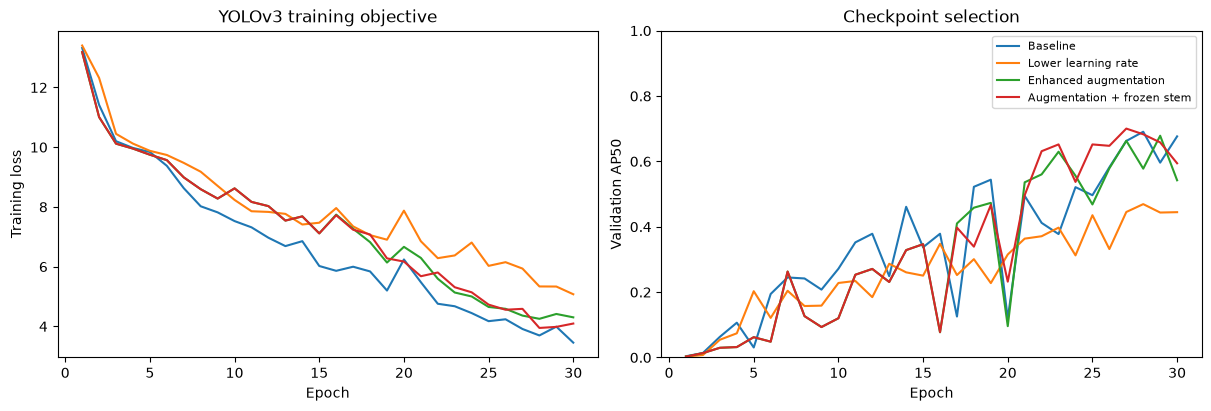

In [5]:
display(pd.DataFrame(metadata["experiments"]))
print(f"Stem freezing begins at epoch {metadata['freeze_stem_epoch']} in its designated run.")
from object_detection.plotting import learning_curves, comparison, precision_recall
learning_curves(result)
plt.show()


## 5. Validation selection and held-out results

AP50 measures bounding-box detection quality at IoU 0.5. It integrates an
interpolated precision–recall curve, using detections with score at least 0.001
and at most 100 detections per image after NMS. It is not classification accuracy
or COCO mAP50:95. The separate precision and recall columns use the fixed score
threshold 0.5; a low-confidence model can have useful AP but low recall there.

The selected configuration maximizes validation AP50. Test metrics below report
all predeclared comparisons, not a second model-selection step.

,model,best_epoch,validation_ap50,training_seconds,test_ap50,test_precision_at_0_5,test_recall_at_0_5,selected_by_validation
0,Baseline,28,0.6907,150.7532,0.6785,0.8056,0.4265,False
1,Lower learning rate,28,0.4693,148.9517,0.4377,0.8235,0.2059,False
2,Enhanced augmentation,29,0.6786,155.0449,0.6440,0.7727,0.5000,False
3,Augmentation + frozen stem,27,0.7004,155.7240,0.5766,0.8261,0.2794,True


Selected using validation: Augmentation + frozen stem, epoch 27.
Validation AP50: 0.700; test AP50: 0.577.


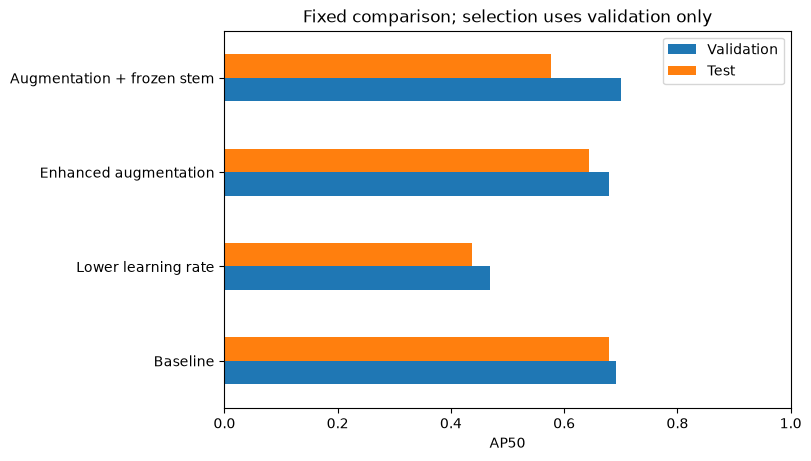

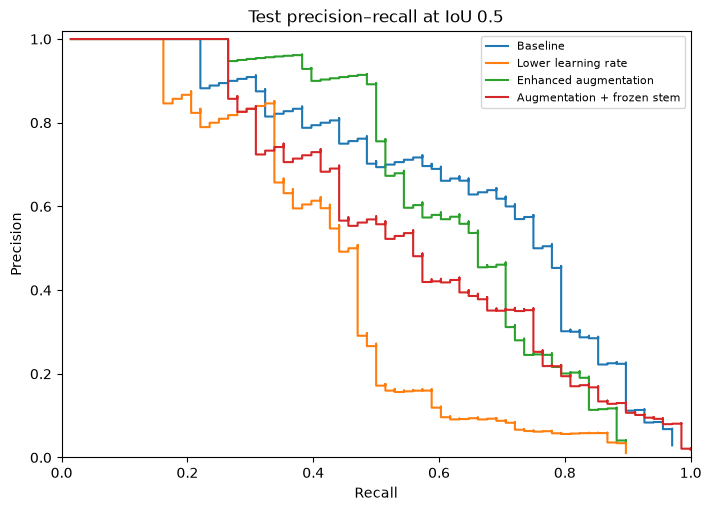

In [6]:
display(result["metrics"].round(4))
chosen = result["metrics"].loc[result["metrics"]["selected_by_validation"]].iloc[0]
print(f"Selected using validation: {chosen['model']}, epoch {int(chosen['best_epoch'])}.")
print(f"Validation AP50: {chosen['validation_ap50']:.3f}; test AP50: {chosen['test_ap50']:.3f}.")
comparison(result)
plt.show()
precision_recall(result)
plt.show()


## 6. Interpret the run

Use the computed comparisons below to describe this particular run, rather than
assuming that stronger augmentation, smaller learning rates, or freezing must
help. Each reported model is its best validation checkpoint; a lower training
loss alone does not determine which one is selected.

In [7]:
metrics = result["metrics"].set_index("model")
baseline = metrics.loc["Baseline"]
for name in metrics.index[1:]:
    row = metrics.loc[name]
    delta = row["validation_ap50"] - baseline["validation_ap50"]
    print(f"{name}: validation AP50 change vs baseline = {delta:+.3f}; "
          f"selected epoch = {int(row['best_epoch'])}.")
frozen = metrics.loc["Augmentation + frozen stem"]
if frozen["best_epoch"] < metadata["freeze_stem_epoch"]:
    print("The freeze run selected a pre-freeze checkpoint; its reported score does not measure freezing's benefit.")
else:
    print("The freeze run selected a post-freeze checkpoint; compare its whole validation curve with augmentation alone.")

if baseline["test_ap50"] > chosen["test_ap50"]:
    print("The baseline has higher reported test AP50 than the validation-selected model.")
    print("Selection is kept fixed: the validation advantage did not carry over to this test split.")
print("A smaller learning rate may need a longer schedule; this comparison fixes the epoch budget.")


Lower learning rate: validation AP50 change vs baseline = -0.221; selected epoch = 28.
Enhanced augmentation: validation AP50 change vs baseline = -0.012; selected epoch = 29.
Augmentation + frozen stem: validation AP50 change vs baseline = +0.010; selected epoch = 27.
The freeze run selected a post-freeze checkpoint; compare its whole validation curve with augmentation alone.
The baseline has higher reported test AP50 than the validation-selected model.
Selection is kept fixed: the validation advantage did not carry over to this test split.
A smaller learning rate may need a longer schedule; this comparison fixes the epoch budget.


## Limits and next steps

- Only one split and one seed are reported. Small differences are not evidence
  of consistent superiority across datasets or random seeds.
- Exact duplicate grouping reduces one leakage source, but similar viewpoints
  and related scenes can still make this an optimistic demonstration. Duplicate
  rows are retained within their assigned split, so they still weight the metrics.
- Direct square resizing changes aspect ratios. Anchor/cell collisions can drop
  an assignment in crowded scenes. This small one-class detector is not intended
  as a production system or full COCO benchmark.
- Future work could compare longer training, repeated splits, and a separately
  licensed larger dataset. Do not repeatedly tune using this reported test set.
- Original photos, annotations, and model weights are not included. Readers can
  reproduce the aggregate analysis immediately; retraining requires authorized
  local data. Source attribution does not grant image redistribution rights.

The mathematical decoding/loss adaptation has an explicit BSD-3-Clause source
and retained notice. The [source notice](../THIRD_PARTY_NOTICES.md) documents the
MathWorks antecedent and the boundary between source-code and dataset rights.
